# Derivative times
One constraint Jacobian and one Lagrangian Hessian at the start point of the timed control period: ours on the supports' structure, CasADi's own Jacobian of Sound-LSE and of GMR. Times are this machine's; the paper's (AMD Ryzen 9 7950X, 12 threads) are read from `results/`. The thread count of our derivatives is the number of CPUs the process may use (12 or 1 in the paper).

In [1]:
import os

os.environ["JAX_PLATFORMS"] = "cpu"
os.environ.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")  # MUMPS and its BLAS on one thread, as the paper's solves ran
import jax
import numpy as np

jax.config.update("jax_enable_x64", True)
import time

import casadi as ca
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline

from common import HES, JAC, SCENES, build, paper, paper_rows, timed, timed_period
from sparsemax_dstl.mpc import baselines as B
from sparsemax_dstl.mpc import ipopt as MI
from sparsemax_dstl.mpc import program as MP
from sparsemax_dstl.sparse import assembly as SA

matplotlib_inline.backend_inline.set_matplotlib_formats("svg")
print("CPUs", len(os.sched_getaffinity(0)))

CPUs 8


Ours: the structures declared from the supports at the start point; every call evaluates the supports at the point again. The Hessian with objective weight 1 and every multiplier 1.

In [2]:
def ours(pb):
    w = jnp.asarray(pb.reference())
    rt = SA.StructuralDerivatives(pb)
    rt.declare(np.asarray(rt.prefix(w)), jnp.float64)
    lam = jnp.ones(pb.m)
    return timed(lambda: rt.jacobian_at(w, object())), timed(lambda: rt.hessian_at(w, object(), 1.0, lam))

CasADi: the constraint Jacobian `nlp_jac_g` of the solver object IPOPT calls (L-BFGS), in CasADi's default evaluation.

In [3]:
def casadi_jacobian(scene, conjs, k, smoothing):
    p = B.Period(scene, conjs, k, smoothing)
    t = time.perf_counter()
    F = ca.nlpsol("period", "ipopt", p.nlp(), MI.ipopt_options("limited-memory")).get_function("nlp_jac_g")
    build_s = time.perf_counter() - t
    w = p.reference()
    return timed(lambda: F(w, [])), build_s

One scene and horizon: our two times, CasADi's two Jacobians, each beside the paper's (in ms).

In [4]:
times = {}


def compare(name, T):
    scene, conjs = build(SCENES[name](T))
    k = timed_period(scene, conjs)
    j, h = ours(MP.PeriodProgram(scene, conjs, k))
    jl, bl = casadi_jacobian(scene, conjs, k, "lse")
    jg, bg = casadi_jacobian(scene, conjs, k, "gmr")
    times[name, T] = {"ours": (j, h), "lse": jl}
    m = dict(scene=name, horizon=T)
    print(name, "T", T, "control period", k)
    print("  ours Jacobian", round(j * 1e3, 2), "| paper", round(paper("counts", comparator="SparseMax (ours)", quantity=JAC + " time", **m) * 1e3, 2),
          "| paper on one thread", round(paper("threads", threads="JAX 1", quantity=JAC + " time", **m) * 1e3, 2))
    print("  ours Hessian", round(h * 1e3, 2), "| paper", round(paper("counts", comparator="SparseMax (ours)", quantity=HES + " time", **m) * 1e3, 2),
          "| paper on one thread", round(paper("threads", threads="JAX 1", quantity=HES + " time", **m) * 1e3, 2))
    print("  Sound-LSE Jacobian", round(jl * 1e3, 2), "| paper", round(paper("counts", comparator="Sound-LSE", quantity=JAC + " time", **m) * 1e3, 2), "| build", round(bl, 1), "s")
    print("  GMR Jacobian", round(jg * 1e3, 2), "| paper", round(paper("counts", comparator="GMR", quantity=JAC + " time", **m) * 1e3, 2), "| build", round(bg, 1), "s")

In [5]:
compare("five-cell zone", 100)

five-cell zone T 100 control period 100
  ours Jacobian 1.82 | paper 2.67 | paper on one thread 4.9
  ours Hessian 2.88 | paper 4.69 | paper on one thread 10.36
  Sound-LSE Jacobian 2.71 | paper 2.62 | build 1.3 s
  GMR Jacobian 2.47 | paper 2.68 | build 1.4 s


In [6]:
compare("five-cell zone", 200)

five-cell zone T 200 control period 100
  ours Jacobian 3.17 | paper 3.69 | paper on one thread 7.8
  ours Hessian 6.36 | paper 6.88 | paper on one thread 15.09
  Sound-LSE Jacobian 5.41 | paper 5.85 | build 4.5 s
  GMR Jacobian 6.65 | paper 5.84 | build 4.5 s


In [7]:
compare("64-cell circle", 100)

64-cell circle T 100 control period 233
  ours Jacobian 6.17 | paper 5.12 | paper on one thread 6.43
  ours Hessian 10.18 | paper 11.18 | paper on one thread 19.25
  Sound-LSE Jacobian 20.03 | paper 19.69 | build 18.7 s
  GMR Jacobian 18.2 | paper 19.73 | build 20.7 s


In [8]:
compare("64-cell circle", 200)

64-cell circle T 200 control period 233
  ours Jacobian 39.37 | paper 21.75 | paper on one thread 28.29
  ours Hessian 65.46 | paper 53.25 | paper on one thread 123.05
  Sound-LSE Jacobian 104.24 | paper 103.28 | build 172.9 s
  GMR Jacobian 95.19 | paper 88.69 | build 191.3 s


The paper's times of dense AD and of CasADi's exact Hessian (one call takes 26.6 s to 817 s, and CasADi's exact Hessian needs 14 GB to build at 100 time steps; `scripts/dense.py` and `scripts/casadi_exact_hessian.py` run them).

In [9]:
for name, q in (("five-cell zone", HES), ("64-cell circle", JAC)):
    for T in (100, 200, 400):
        m = dict(scene=name, horizon=T, quantity=q + " time")
        line = name + " " + q + " T " + str(T) + " | dense AD " + str(round(paper("counts", comparator="dense AD", **m), 1)) + " s"
        lse = paper_rows("counts", comparator="Sound-LSE", variant="CasADi's exact Hessian", **m) if q == HES else []
        if lse:
            line += " | CasADi's exact Hessian " + str(round(float(lse[0]["value"]), 3)) + " s"
        print(line)

five-cell zone Hessian of the Lagrangian T 100 | dense AD 26.6 s | CasADi's exact Hessian 0.339 s
five-cell zone Hessian of the Lagrangian T 200 | dense AD 109.6 s | CasADi's exact Hessian 1.103 s
five-cell zone Hessian of the Lagrangian T 400 | dense AD 476.4 s
64-cell circle constraint Jacobian T 100 | dense AD 3.9 s
64-cell circle constraint Jacobian T 200 | dense AD 27.4 s
64-cell circle constraint Jacobian T 400 | dense AD 137.2 s


Panels (b) and (c) of the results figure with this machine's times of ours and of Sound-LSE's Jacobian and the paper's dense AD and exact Hessian; saved as `out/derivative-times` (SVG and PDF).

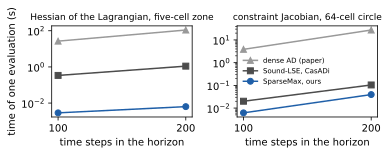

In [10]:
Ts = [100, 200]
os.makedirs("out", exist_ok=True)
fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.2))
for ax, name, q, i in ((axs[0], "five-cell zone", HES, 1), (axs[1], "64-cell circle", JAC, 0)):
    ax.plot(Ts, [paper("counts", scene=name, horizon=T, quantity=q + " time", comparator="dense AD") for T in Ts], "^-", color="0.6", label="dense AD (paper)")
    if q == JAC:
        ax.plot(Ts, [times[name, T]["lse"] for T in Ts], "s-", color="0.3", label="Sound-LSE, CasADi")
    else:
        ax.plot(Ts, [paper("counts", scene=name, horizon=T, quantity=q + " time", comparator="Sound-LSE") for T in Ts], "s-", color="0.3", label="Sound-LSE, CasADi (paper)")
    ax.plot(Ts, [times[name, T]["ours"][i] for T in Ts], "o-", color="#1f5fa8", label="SparseMax, ours")
    ax.set_yscale("log")
    ax.set_xticks(Ts)
    ax.set_xlabel("time steps in the horizon")
    ax.set_title(q + ", " + name, fontsize=9)
axs[0].set_ylabel("time of one evaluation (s)")
axs[1].legend(fontsize=7, frameon=False)
fig.tight_layout()
for ext in ("svg", "pdf"):
    fig.savefig("out/derivative-times." + ext, metadata={"Creator": None, "Date": None} if ext == "svg" else {"Creator": None, "Producer": None, "CreationDate": None})